In [ ]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate dummy data for 1000 users
n_users = 1000

user_ids = [f"USR_{i:04d}" for i in range(1, n_users + 1)]
ages = np.random.randint(21, 65, size=n_users)
annual_income = np.random.randint(30000, 150000, size=n_users)
credit_score = np.random.randint(300, 850, size=n_users)
loan_amount = np.random.randint(5000, 80000, size=n_users)
employment_status = np.random.choice(['Employed', 'Self-Employed', 'Unemployed'], size=n_users, p=[0.7, 0.2, 0.1])

# Create DataFrame with exactly 6 initial columns
df = pd.DataFrame({
    'User_ID': user_ids,
    'Age': ages,
    'Annual_Income': annual_income,
    'Credit_Score': credit_score,
    'Loan_Amount': loan_amount,
    'Employment_Status': employment_status
})

# Logic to determine the 7th column (Loan_Status)
loan_status = []
for idx, row in df.iterrows():
    if row['Employment_Status'] == 'Unemployed':
        status = 'Rejected'
    elif row['Credit_Score'] < 550:
        status = 'Rejected'
    elif row['Loan_Amount'] > (row['Annual_Income'] * 0.6):
        status = 'Rejected'
    elif row['Credit_Score'] > 700:
        status = 'Approved'
    else:
        # Probabilistic approval for medium credit scores
        status = np.random.choice(['Approved', 'Rejected'], p=[0.6, 0.4])
    loan_status.append(status)

# Add the 7th column
df['Loan_Status'] = loan_status

# Display summary details
print(f"Dataset Shape (Rows, Columns): {df.shape}")
print("\nFirst 5 rows:")
display(df.head())
print("\nLoan Status Distribution:")
print(df['Loan_Status'].value_counts())


Dataset Shape (Rows, Columns): (1000, 7)

First 5 rows:


,User_ID,Age,Annual_Income,Credit_Score,Loan_Amount,Employment_Status,Loan_Status
0,USR_0001,59,34018,669,35795,Unemployed,Rejected
1,USR_0002,49,41302,563,13770,Self-Employed,Approved
2,USR_0003,35,97506,617,16093,Employed,Rejected
3,USR_0004,63,71157,383,51571,Self-Employed,Rejected
4,USR_0005,28,84917,617,5193,Employed,Rejected



Loan Status Distribution:
Loan_Status
Rejected    740
Approved    260
Name: count, dtype: int64


### Logistic Regression Model
We will preprocess the data and train a Logistic Regression model to classify whether a loan will be Approved (1) or Rejected (0).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Define features and target
X = df.drop(columns=['User_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

# Identify column types
num_cols = ['Age', 'Annual_Income', 'Credit_Score', 'Loan_Amount']
cat_cols = ['Employment_Status']

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Preprocess features
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Output performance
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))


Accuracy Score: 0.8650

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.88      0.95      0.91       148
    Approved       0.80      0.63      0.71        52

    accuracy                           0.86       200
   macro avg       0.84      0.79      0.81       200
weighted avg       0.86      0.86      0.86       200



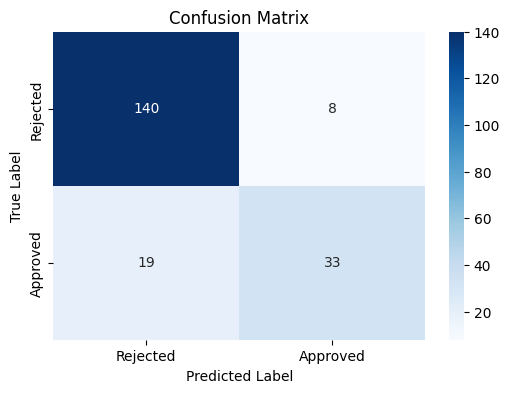

In [ ]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


### Bias and Variance Diagnosis using Learning Curves
To check for bias and variance, we can plot the training and validation accuracy as a function of the training set size.
- **High Bias (Underfitting)**: Both training and validation scores are low, and they converge quickly.
- **High Variance (Overfitting)**: There is a significant gap between the high training score and the lower validation score.

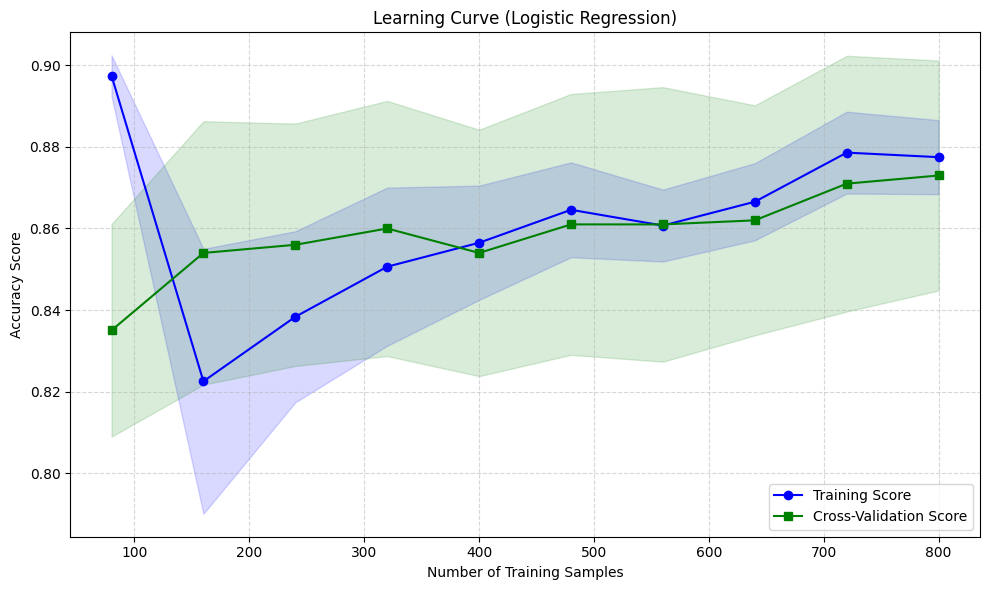

In [ ]:
import numpy as np
from sklearn.model_selection import learning_curve

# Calculate learning curve values
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=LogisticRegression(random_state=42),
    X=preprocessor.fit_transform(X),
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    random_state=42
)

# Calculate mean and standard deviation for training and validation sets
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# Plot the learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, validation_mean, 's-', color='green', label='Cross-Validation Score')
plt.fill_between(train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.15, color='green')

plt.title('Learning Curve (Logistic Regression)')
plt.xlabel('Number of Training Samples')
plt.ylabel('Accuracy Score')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Loan Status Proportions
Let's visualize the exact percentage of Approved vs. Rejected loans in our dataset using a pie chart.

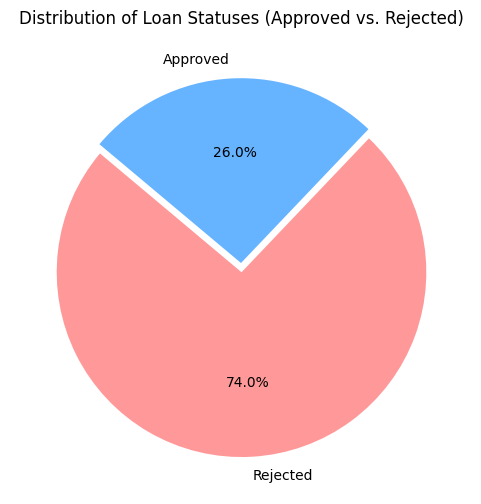

In [ ]:
# Plotting the proportion of Loan Statuses
status_counts = df['Loan_Status'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff9999', '#66b3ff'],
    explode=(0.05, 0)
)
plt.title('Distribution of Loan Statuses (Approved vs. Rejected)')
plt.show()

### Test Custom Input
Use the form fields below to adjust the features and see the model's prediction in real-time.

In [35]:
#@title Interactive Model Tester { run: "auto" }

# Form variables
Age = 28 #@param {type:"integer"}
Annual_Income = 200000 #@param {type:"integer"}
Credit_Score = 748 #@param {type:"slider", min:300, max:850, step:1}
Loan_Amount = 14000 #@param {type:"integer"}
Employment_Status = "Employed" #@param ["Employed", "Self-Employed", "Unemployed"]

# Create a DataFrame from the input
custom_data = pd.DataFrame({
    'Age': [Age],
    'Annual_Income': [Annual_Income],
    'Credit_Score': [Credit_Score],
    'Loan_Amount': [Loan_Amount],
    'Employment_Status': [Employment_Status]
})

# Transform the input using our fitted preprocessor
custom_scaled = preprocessor.transform(custom_data)

# Predict using the trained model
prediction = model.predict(custom_scaled)[0]
probabilities = model.predict_proba(custom_scaled)[0]

# Map the prediction back to label
status_mapping = {1: 'Approved', 0: 'Rejected'}
predicted_label = status_mapping[prediction]

# Display the results
print("=== Custom Input Evaluation ===")
display(custom_data)
print("\n--- Prediction Result ---")
print(f"Predicted Status: {predicted_label.upper()}")
print(f"Probability of Approval: {probabilities[1]*100:.2f}%")
print(f"Probability of Rejection: {probabilities[0]*100:.2f}%")


=== Custom Input Evaluation ===


,Age,Annual_Income,Credit_Score,Loan_Amount,Employment_Status
0,28,200000,748,14000,Employed



--- Prediction Result ---
Predicted Status: APPROVED
Probability of Approval: 99.60%
Probability of Rejection: 0.40%
